## Задача 5. Обучение без учителя
- [x] Найти данные с количеством признаков хотя бы 50, на которых можно решить задачу кластеризации.
- [x] Выполнить разведочный анализ (EDA). При необходимости выполнить полезные преобразования данных.
- [x] Самостоятельно реализуйте один из алгоритмов кластеризации, например K-means.
- [x] Обучите модели кластеризации, используя свою реализацию, а также хотя бы две реализации из sklearn (KMeans, Affinity Propogation, DBSCAN и тд).
- [x] При обучении использовать подбор гиперпараметров.
- [x] Сравнить качество моделей: замерить скорость обучения, вычислить различные метрики качества.
- [x] * (+3 балла) Также снизить размерность данных с помощью метода главных компонент PCA и понять качество дальнейшей кластеризации всеми использованными реализациями при различном количестве главных компонент.
- [x] * (+2 балла) Визуализировать данные снижением размерности до 2 или 3 с помощью PCA и t-SNE. В случае проблем с производительностью t-SNE, можно сначала до какой то степени снизить размерность с помощью PCA, а затем запустить t-SNE.

### Подготовка библиотек и данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from time import time
import seaborn as sb
from sklearn import datasets
from sklearn.cluster import KMeans, AffinityPropagation
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [2]:
digits = datasets.load_digits()
X = digits.data
y_target = digits.target
df = pd.DataFrame(X)

In [3]:
df

,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1792,0.0,0.0,4.0,10.0,13.0,6.0,0.0,0.0,0.0,1.0,...,4.0,0.0,0.0,0.0,2.0,14.0,15.0,9.0,0.0,0.0
1793,0.0,0.0,6.0,16.0,13.0,11.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,6.0,16.0,14.0,6.0,0.0,0.0
1794,0.0,0.0,1.0,11.0,15.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,9.0,13.0,6.0,0.0,0.0
1795,0.0,0.0,2.0,10.0,7.0,0.0,0.0,0.0,0.0,0.0,...,2.0,0.0,0.0,0.0,5.0,12.0,16.0,12.0,0.0,0.0


Датасет digits состоит из картинок с цифрами, в каждой по 64 пикселя со значениями 0--16.

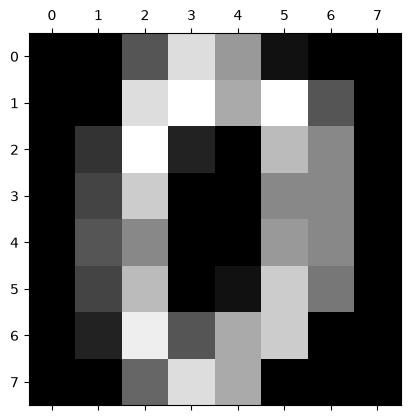

In [4]:
plt.matshow(digits.images[0], cmap="gray")
plt.show()

In [5]:
df.isnull().sum().sum() == 0

np.True_

Все значения непустые.

In [6]:
df.duplicated().any()

np.False_

Нет повторов.

### Реализация алгоритма K-Means (MyKMeans)

In [7]:
class MyKMeans:
    def __init__(self, n_clusters=10, max_iter=300, tol=1e-4, random_state=None, n_init=10):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.n_init = n_init
        self.centroids = None
        self.labels_ = None
        self.inertia_ = None

    def _init_centroids(self, X, rng):
        n_samples = X.shape[0]

        centroids = [X[rng.randint(n_samples)]]
        for _ in range(1, self.n_clusters):
            dist_sq = np.array([min(np.sum((x - c) ** 2) for c in centroids) for x in X])
            total_dist = dist_sq.sum()
            if total_dist == 0:
                probs = np.ones(n_samples) / n_samples
            else:
                probs = dist_sq / total_dist
            
            cumulative_probs = probs.cumsum()
            r = rng.rand()
            idx = np.searchsorted(cumulative_probs, r)
            centroids.append(X[idx])
        return np.array(centroids)

    def _assign_clusters(self, X, centroids):
        distances = np.sqrt(((X[:, np.newaxis] - centroids) ** 2).sum(axis=2))
        return np.argmin(distances, axis=1)

    def _update_centroids(self, X, labels, current_centroids):
        new_centroids = np.zeros_like(current_centroids)
        for k in range(self.n_clusters):
            cluster_points = X[labels == k]
            if len(cluster_points) > 0:
                new_centroids[k] = cluster_points.mean(axis=0)
            else:
                new_centroids[k] = current_centroids[k]
        return new_centroids

    def fit(self, X):
        X = np.array(X)
        
        if self.random_state is not None:
            base_rng = np.random.RandomState(self.random_state)
            seeds = base_rng.randint(0, np.iinfo(np.int32).max, size=self.n_init)
        else:
            seeds = [None] * self.n_init

        best_inertia = float('inf')
        best_centroids = None
        best_labels = None

        for init_idx in range(self.n_init):
            rng = np.random.RandomState(seeds[init_idx])
            
            current_centroids = self._init_centroids(X, rng)
            current_labels = None

            for i in range(self.max_iter):
                old_centroids = current_centroids.copy()
                current_labels = self._assign_clusters(X, current_centroids)
                current_centroids = self._update_centroids(X, current_labels, current_centroids)

                shift = np.sum((current_centroids - old_centroids) ** 2)
                if shift < self.tol:
                    break

            current_labels = self._assign_clusters(X, current_centroids)
            current_inertia = np.sum((X - current_centroids[current_labels]) ** 2)

            if current_inertia < best_inertia:
                best_inertia = current_inertia
                best_centroids = current_centroids
                best_labels = current_labels

        self.centroids = best_centroids
        self.labels_ = best_labels
        self.inertia_ = best_inertia
        return self

    def predict(self, X):
        X = np.array(X)
        if self.centroids is None:
            raise RuntimeError("сначала нужно вызвать fit()")
        return self._assign_clusters(X, self.centroids)

    def fit_predict(self, X):
        self.fit(X)
        return self.labels_


### Обучение

Сравним следующие методы:
1. sklearn.KMeans
2. Affinity Propagation
3. MyKMeans

Будем собирать следующие метрики: `ARI` (т.к. известны истинные кластеры), `NMI` (аналогично), `silhouette`, `davies_bouldin_score`, `calinski_harabasz_score`.

При обучении используем подбор гиперпараметров.

Результаты будем сортировать по `ARI`.

#### Вспомогательные функции

In [8]:
def fit_count_metrics(lst, model, X, params, model_name):
    start_time = time()
    y = model.fit_predict(X)
    fit_time = time() - start_time
    n_clusters = len(np.unique(y))

    if 1 < n_clusters < len(X):
        sil = silhouette_score(X, y)
        ch = calinski_harabasz_score(X, y)
        db = davies_bouldin_score(X, y)
    else:
        sil, ch, db = np.nan, np.nan, np.nan

    ari = adjusted_rand_score(y_target, y)
    nmi = normalized_mutual_info_score(y_target, y)

    data = {
        'model_name': model_name,
        'params': params,
        'fit_time_s': fit_time,
        'ari': ari,
        'nmi': nmi,
        'n_clusters': n_clusters,
        'silhouette': sil,
        'calinski_harabasz': ch,
        'davies_bouldin': db
    }
    lst.append(data)

#### Кластеризация с помощью sklearn.Kmeans, sklearn.AffinityPropagation и MyKMeans

In [9]:
n_clusters = 10

distances = euclidean_distances(X)
neg_med = -np.median(distances ** 2) 
base_preference = neg_med * 10

results = []

for init in ["k-means++", "random"]:
    for algo in ["lloyd", "elkan"]:
        kmeans = KMeans(init=init, n_clusters=n_clusters, algorithm=algo, random_state=42)
        params = {"init": init, "algo": algo}
        fit_count_metrics(results, kmeans, X, params, 'sklearn.Kmeans')

for coef in range(1, 10):
    preference = base_preference * coef
    for damping in [0.8, 0.9, 0.95]:
        ap = AffinityPropagation(damping=damping, preference=preference, random_state=42)
        params = {"damping": damping, "coef": coef, "preference": preference}
        fit_count_metrics(results, ap, X, params, 'Affinity Propagation')

for n_init in range(5, 10):
    my_kmeans = MyKMeans(n_clusters=n_clusters, n_init=n_init, random_state=42)
    params = {"n_clusters": n_clusters, "n_init": n_init}
    fit_count_metrics(results, my_kmeans, X, params, 'MyKMeans')

### Результаты

In [10]:
results_df = pd.DataFrame(results)

sorted_df = results_df.sort_values(["ari", "silhouette", "fit_time_s"], ascending=[False, False, False])

sorted_df.head(15)

,model_name,params,fit_time_s,ari,nmi,n_clusters,silhouette,calinski_harabasz,davies_bouldin
0,sklearn.Kmeans,"{'init': 'k-means++', 'algo': 'lloyd'}",0.031505,0.725814,0.774997,10,0.176474,162.368008,2.045395
1,sklearn.Kmeans,"{'init': 'k-means++', 'algo': 'elkan'}",0.015913,0.725814,0.774997,10,0.176474,162.368008,2.045395
9,Affinity Propagation,"{'damping': 0.95, 'coef': 2, 'preference': -48...",4.075603,0.673868,0.725626,11,0.172047,155.454071,2.027927
3,sklearn.Kmeans,"{'init': 'random', 'algo': 'elkan'}",0.106399,0.663415,0.737464,10,0.182236,169.327449,1.919217
2,sklearn.Kmeans,"{'init': 'random', 'algo': 'lloyd'}",0.040427,0.663415,0.737464,10,0.182236,169.327449,1.919217
11,Affinity Propagation,"{'damping': 0.9, 'coef': 3, 'preference': -723...",2.607724,0.662516,0.727342,10,0.172711,162.607933,2.001500
35,MyKMeans,"{'n_clusters': 10, 'n_init': 9}",3.648890,0.659936,0.742319,10,0.182171,169.251932,1.925288
34,MyKMeans,"{'n_clusters': 10, 'n_init': 8}",3.075523,0.659936,0.742319,10,0.182171,169.251932,1.925288
33,MyKMeans,"{'n_clusters': 10, 'n_init': 7}",2.719120,0.659936,0.742319,10,0.182171,169.251932,1.925288
32,MyKMeans,"{'n_clusters': 10, 'n_init': 6}",2.361972,0.659936,0.742319,10,0.182171,169.251932,1.925288


Посмотрим на лучшие результаты для каждой модели:

In [11]:
models_best = (
    sorted_df.sort_values(
        ["model_name", "ari", "silhouette"], ascending=[True, False, False]
    )
    .groupby("model_name", as_index=False)
    .head(1)
    .sort_values("ari", ascending=False)
    .reset_index(drop=True)
)

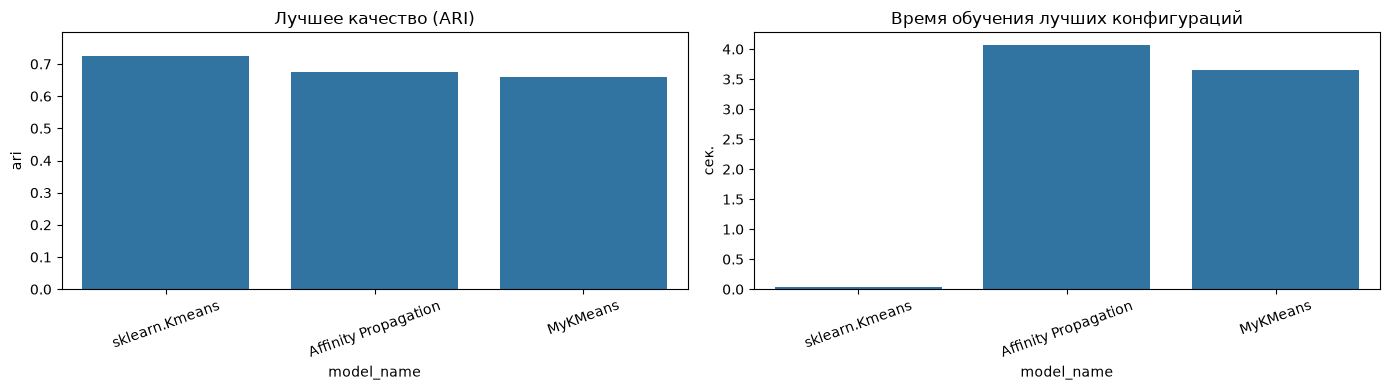

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sb.barplot(data=models_best, x="model_name", y="ari", ax=axes[0])
axes[0].set_title("Лучшее качество (ARI)")
axes[0].set_ylim(0, max(0.1, models_best["ari"].max() * 1.1))
axes[0].tick_params(axis="x", rotation=20)

sb.barplot(data=models_best, x="model_name", y="fit_time_s", ax=axes[1])
axes[1].set_title("Время обучения лучших конфигураций")
axes[1].set_ylabel("сек.")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### Анализ результатов

Алгоритмы вышли сопоставимыми по качеству, однако оптимизированный `sklearn.Kmeans` на порядок превосходит остальные алгоритмы по производительности.

## Понижение размерности и визуализация

### Анализ качества PCA для разного количества компонент

In [13]:
n_components_list = [2, 5, 10, 15, 20, 30, 40, 50, 60]

pca_results = []

for n_components in n_components_list:
    pca = PCA(n_components=n_components, random_state=42)
    X_pca = pca.fit_transform(X)

    new_results = []

    for algo in ["lloyd", "elkan"]:
        init = "k-means++"
        kmeans = KMeans(init=init, n_clusters=n_clusters, algorithm=algo, random_state=42)
        params = {"init": init, "algo": algo}
        fit_count_metrics(new_results, kmeans, X_pca, params, 'sklearn.Kmeans')
    
    for coef in range(2, 4):
        preference = base_preference * coef
        for damping in [0.8, 0.9, 0.95]:
            ap = AffinityPropagation(damping=damping,preference=preference, random_state=42)
            params = {"damping": damping, "coef": coef, "preference": preference}
            fit_count_metrics(new_results, ap, X_pca, params, 'Affinity Propagation')

    for n_init in range(5, 10):
        my_kmeans = MyKMeans(n_clusters=n_clusters, n_init=n_init, random_state=42)
        params = {"n_init": n_init}
        fit_count_metrics(new_results, my_kmeans, X_pca, params, 'MyKMeans')

    for res in new_results:
        res['n_components'] = n_components
        
    pca_results += new_results


pca_results_df = pd.DataFrame(pca_results)

pca_models_best = pca_results_df.sort_values(["ari", "silhouette", "fit_time_s", "n_components"], ascending=[False, False, False, False])

pca_models_best.head(5)

,model_name,params,fit_time_s,ari,nmi,n_clusters,silhouette,calinski_harabasz,davies_bouldin,n_components
91,sklearn.Kmeans,"{'init': 'k-means++', 'algo': 'lloyd'}",0.104957,0.730905,0.778197,10,0.176631,162.454463,2.046720,50
92,sklearn.Kmeans,"{'init': 'k-means++', 'algo': 'elkan'}",0.045138,0.730905,0.778197,10,0.176631,162.454463,2.046720,50
104,sklearn.Kmeans,"{'init': 'k-means++', 'algo': 'lloyd'}",0.105631,0.725814,0.774997,10,0.176474,162.368108,2.045394,60
105,sklearn.Kmeans,"{'init': 'k-means++', 'algo': 'elkan'}",0.039827,0.725814,0.774997,10,0.176474,162.368108,2.045394,60
59,Affinity Propagation,"{'damping': 0.95, 'coef': 3, 'preference': -72...",3.912073,0.699557,0.738619,10,0.192395,186.003284,2.013125,20


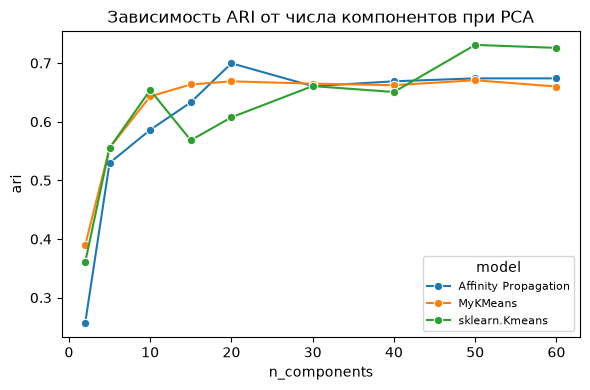

In [14]:
pca_models_cluster = pca_models_best.sort_values(
        ["n_components", "model_name", "ari", "silhouette"],
        ascending=[True, True, False, False],
    ).groupby(["n_components", "model_name"], as_index=False).head(1).reset_index(drop=True)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))

sb.lineplot(
    data=pca_models_cluster,
    x="n_components",
    y="ari",
    hue="model_name",
    marker="o",
    ax=ax,
)
ax.set_title("Зависимость ARI от числа компонентов при PCA")
ax.legend(title="model", fontsize=8)

plt.tight_layout()
plt.show()

### Визуализация

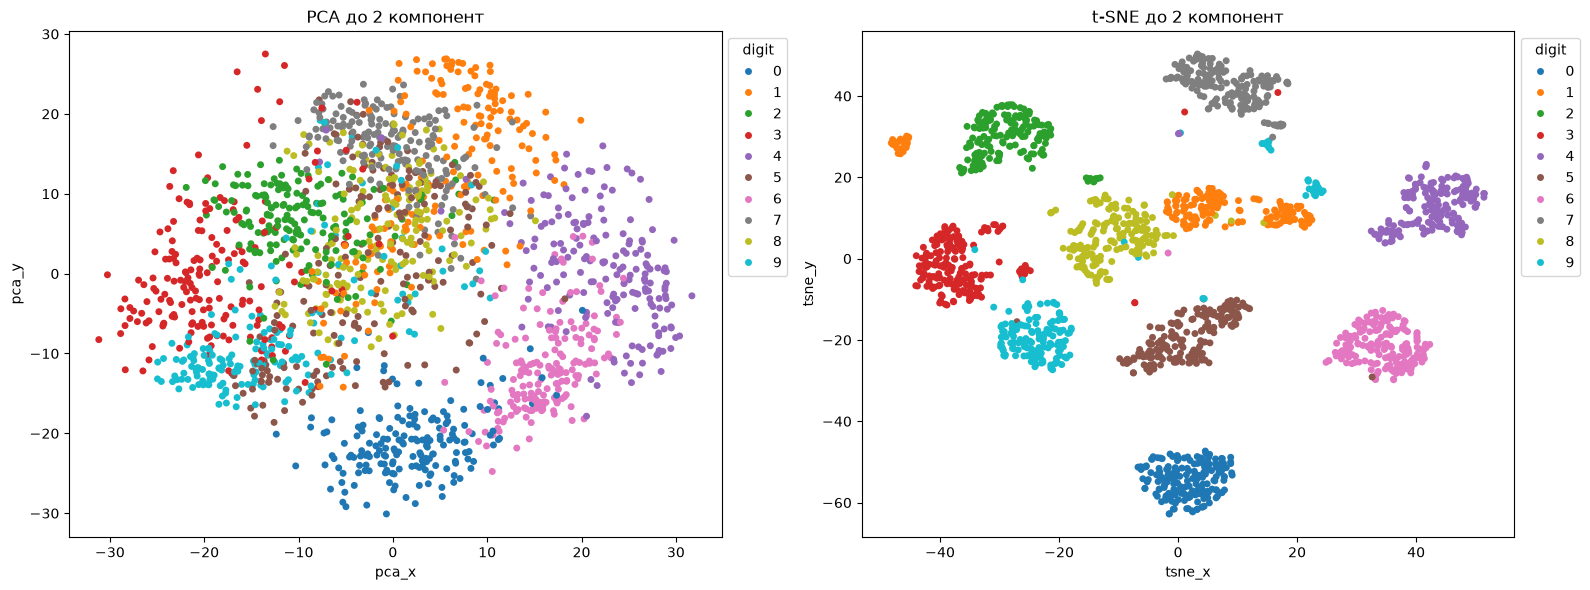

In [15]:
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X)

tsne = TSNE(n_components=2, random_state=42)
X_tsne_2d = tsne.fit_transform(X)

plot_df = pd.DataFrame(
    {
        "pca_x": X_pca_2d[:, 0],
        "pca_y": X_pca_2d[:, 1],
        "tsne_x": X_tsne_2d[:, 0],
        "tsne_y": X_tsne_2d[:, 1],
        "digit": y_target.astype(str),
    }
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sb.scatterplot(
    data=plot_df,
    x="pca_x",
    y="pca_y",
    hue="digit",
    palette="tab10",
    s=25,
    linewidth=0,
    ax=axes[0],
)
axes[0].set_title("PCA до 2 компонент")
axes[0].legend(title="digit", bbox_to_anchor=(1, 1), loc="upper left", fontsize=10)

sb.scatterplot(
    data=plot_df,
    x="tsne_x",
    y="tsne_y",
    hue="digit",
    palette="tab10",
    s=25,
    linewidth=0,
    ax=axes[1],
)
axes[1].set_title("t-SNE до 2 компонент")
axes[1].legend(title="digit", bbox_to_anchor=(1, 1), loc="upper left", fontsize=10)

plt.tight_layout()
plt.show()

In [16]:
models_best_row = models_best.iloc[0]
pca_best_row = pca_models_best.iloc[0]

print("Лучшее решение без PCA:")
print(
    models_best_row[
        [
            "model_name",
            "params",
            "fit_time_s",
            "n_clusters",
            "ari",
            "silhouette",
        ]
    ]
)

print("\nЛучшее решение с PCA:")
print(
    pca_best_row[
        [
            "model_name",
            "n_components",
            "params",
            "fit_time_s",
            "n_clusters",
            "ari",
            "silhouette",
        ]
    ]
)

Лучшее решение без PCA:
model_name                            sklearn.Kmeans
params        {'init': 'k-means++', 'algo': 'lloyd'}
fit_time_s                                  0.031505
n_clusters                                        10
ari                                         0.725814
silhouette                                  0.176474
Name: 0, dtype: object

Лучшее решение с PCA:
model_name                              sklearn.Kmeans
n_components                                        50
params          {'init': 'k-means++', 'algo': 'lloyd'}
fit_time_s                                    0.104957
n_clusters                                          10
ari                                           0.730905
silhouette                                    0.176631
Name: 91, dtype: object


### Выводы

1. Были найдены данные с 64 признаками, пригодные для кластеризации, а именно набор данных `digits`.
2. Реализованная в ходе работы версия алгоритма `MyKMeans` показала результаты, сравнимые с библиотечными функциями `sklearn.KMeans` и `sklearn.AffinityPropagation` и по времени работы оказалась близка к последней. `sklearn.KMeans` оказалась на порядок эффективнее остальных функций.
3. Подбор гиперпараметров позволил достичь оптимального качества на всех алгоритмах. Особенно заметна разница между разными конфигурациями `sklearn.AffinityPropagation` с разными `preference` и `damping`.
4. `PCA` позволил улучшить качество кластеризации на большом количестве главных компонент (50).
5. `T-SNE` позволил достичь лучшей локализации кластеров, чем линейная проекция `PCA`, и лучше подошёл для визуализации.